## Data-Mining Practice 4
### Myrzakassymov Azizkhan 

### Part I. Model Evaluation and Hyperparameter Tuning
#### Tasks 1–4
#### Dataset requirements
Select a dataset suitable for a classification task from Kaggle, UCI Machine Learning
Repository, OpenML, or another reliable source.

Your dataset must:
- Contain at least 500 observations.
- Contain at least 5 input features.
- Have a categorical target variable with at least two classes.
- Be suitable for classification using scikit-learn.

Use the same dataset throughout Part I. Record its name, source, number of observations,
number of features, target variable, and class distribution.

#### Dataset
##### Adult

Donated on 4/30/1996

Predict whether annual income of an individual exceeds $50K/yr based on census data. Also known as "Census Income" dataset.

##### Dataset Characteristics
Multivariate

##### Subject Area
Social Science

##### Associated Tasks
Classification

##### Feature Type
Categorical, Integer

##### Instances
48842

##### Features
14

##### Additional Information

Extraction was done by Barry Becker from the 1994 Census database.  A set of reasonably clean records was extracted using the following conditions: ((AAGE>16) && (AGI>100) && (AFNLWGT>1)&& (HRSWK>0))

Prediction task is to determine whether a person's income is over $50,000 a year.

Dataset source: https://archive.ics.uci.edu/dataset/2/adult

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (
train_test_split,
cross_val_score,
StratifiedKFold,
GridSearchCV,
RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
accuracy_score,
precision_score,
recall_score,
f1_score,
confusion_matrix,
classification_report,
roc_auc_score
)


In [3]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
adult = fetch_ucirepo(id=2) 
  
# data (as pandas dataframes) 
X = pd.DataFrame(adult.data.features)
y = adult.data.targets 
  
display(X)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States
48838,64,NaN,321403,HS-grad,9,Widowed,NaN,Other-relative,Black,Male,0,0,40,United-States
48839,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States
48840,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States


In [4]:
# Inspect the dataset
print(X.head())
print(X.shape)
print(X.info())
print(X.isnull().sum())

   age         workclass  fnlwgt  education  education-num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital-status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital-gain  capital-loss  hours-per-week native-country  
0          2174             0              40  United-States  
1             0             0              13  United-St

Columns 'workclass', 'occupation' and 'native-country' have missing values.

I will impute them with 'Unknown', and also implement pipeline with KNN imputer for numerical data, in hypothetical case if someone will decide to train models on new data.

In [5]:
# Handle missing values and encode categorical variables
# as appropriate for your dataset.
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder

categorical = X.select_dtypes('object').columns.to_list()
numerical = X.select_dtypes('number').columns.to_list()

cat_pipeline = Pipeline( # Imputing and encoding categorical data
    [
        ('imputer', SimpleImputer(strategy='constant', fill_value='most_frequent')),
        ('encoder', OneHotEncoder(sparse_output=False))
    ]
)
num_pipeline = Pipeline( # Imputing and encoding numerical data
    [
        ('imputer', KNNImputer()),
        ('scaler', StandardScaler())
    ]
)

preprocessor = ColumnTransformer( 
    transformers=[
        ('cat', cat_pipeline, categorical),
        ('num', num_pipeline, numerical)
    ]
)


In [6]:
# Split the data
from sklearn.utils import column_or_1d

y = y.squeeze()
y = y.str.rstrip('.')
y = (y == '>50K').astype(int)

# checking class balance
balance = len(y[y == 1])  / len(y)
print('Positive class (>50K) is ', balance, 'of whole dataset')

X_train, X_test, y_train, y_test = train_test_split(
X, column_or_1d(y),
test_size=0.2,
random_state=42,
stratify=y
)

Positive class (>50K) is  0.23928176569346055 of whole dataset


Positive target class is imbalanced, I will note this for the future.

In [13]:
# Classifying pipeline

classifiers = {
    'Logistic Regression' : LogisticRegression(n_jobs=-1),
    'Decision Tree' : DecisionTreeClassifier(),
    'K Nearest Neighbors' : KNeighborsClassifier(n_neighbors=10)
}
pipes = {}
performance_table = pd.DataFrame(
    columns=['Logistic Regression', 'Decision Tree', 'K Nearest Neighbors'],
    index=['Accuracy', 'ROC-AUC', 'Precision', 'Recall', 'F1-score']
)


for classifier in classifiers:
    pipeline = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', classifiers[classifier])
        ]
    )
    pipeline.fit(X_train, y_train)
    pipes[classifier] = pipeline

    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1] 
    
    data = np.array(
        [accuracy_score(y_test, y_pred),
        roc_auc_score(y_test, y_proba),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)]
    )
    performance_table[classifier] = data

display(performance_table)

,Logistic Regression,Decision Tree,K Nearest Neighbors
Accuracy,0.851776,0.812059,0.843996
ROC-AUC,0.905911,0.746454,0.885617
Precision,0.732255,0.604583,0.725610
Recall,0.600086,0.620616,0.559880
F1-score,0.659614,0.612495,0.632062


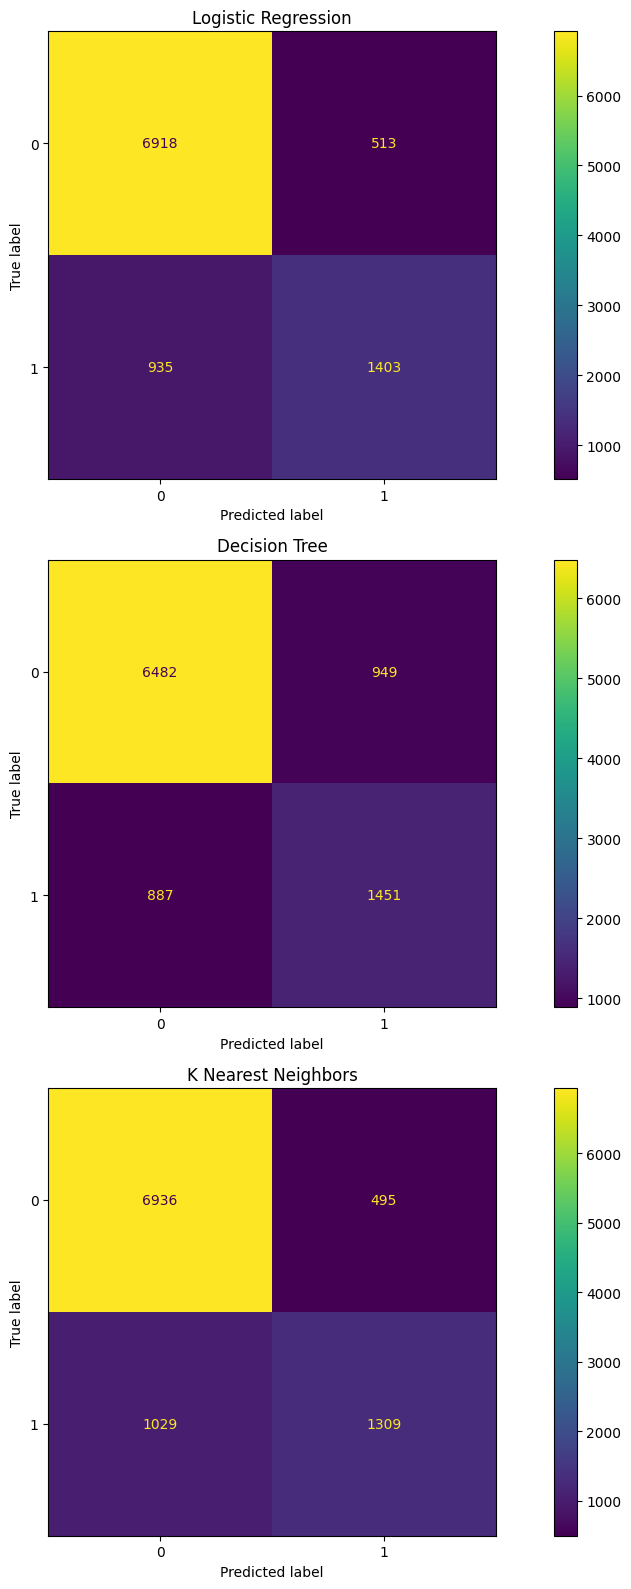

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize = (12, 16), dpi=100, nrows=3)

for i, pipe in enumerate(pipes):
    y_pred = pipes[pipe].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        ax=ax[i]
    )
    ax[i].set_title(pipe)

plt.tight_layout()
plt.show()

Differences between Precision, Recall and F1-Score.

First of all, F1-score is dependent metric, that is born from Precision and Recall as their relations: 2 * Precision * Recall / (Precision + Recall).

Precision is a relation of True Positives and sum of True Positives and False Positives. Basically, if you don't need any false positives (Negatives, but called Positives by model), then you should increase Precision, by increasing threshold (of scoring or probability) for your model to identify observation as positive class.

Recall is a relation of True Positives and sum of True Positives and False Negatives, plays same role as Precision but for False Negatives (Positives, but called Negatives by model).

Both of metrics have a very stochastic function of model thresholds, so you have to tune them, watching on F1-score and PR curve.

In my task there's no specific need to identify if one will have >50k per year salary or not.

I think the real bussiness model